# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_: 
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=-5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

Calculated Root: -0.122357
Iterations taken: 2


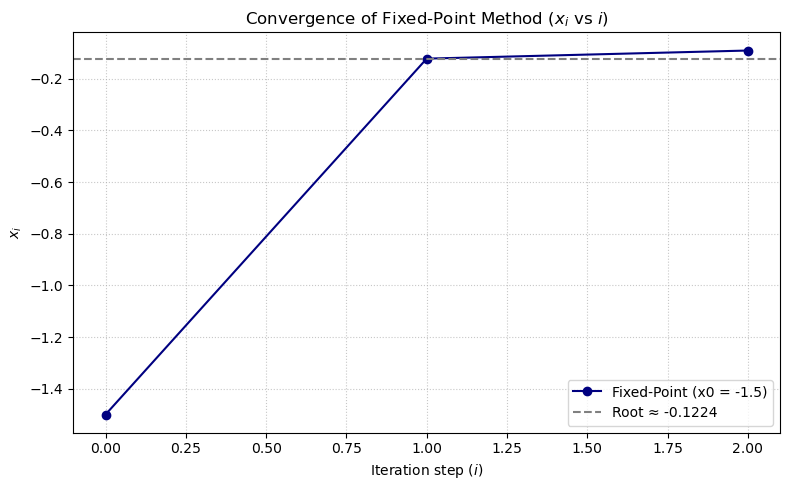

In [25]:
# FIXED THIS FROM AI NI GAGA
# Fixed-Point Method
def fixed_point(g, x0, tol=1e-6, kmax=100):
    history = [x0]  # Store history for convergence tracking
    x = x0
    
    for k in range(kmax):
        xnew = (k - omega) * x + omega * g(x)
        history.append(xnew)
        
        # Check for convergence
        if abs(xnew - x) < tol:
            break
            
        x = xnew
        
    return x, np.array(history)

# --- Execution ---
x0 = -1.5  # Initial guess
omega = 0.05 # Relaxation weight
root, history = fixed_point(g, x0, omega)

print(f"Calculated Root: {root:.6f}")
print(f"Iterations taken: {len(history) - 1}")

# --- Plotting Convergence (x_i vs i) ---
iterations = np.arange(len(history))

plt.figure(figsize=(8, 5))
plt.plot(iterations, history, 'o-', label=f'Fixed-Point (x0 = {x0})', color='navy')
plt.axhline(root, color='gray', linestyle='--', label=f'Root ≈ {root:.4f}')

plt.xlabel('Iteration step ($i$)')
plt.ylabel('$x_i$')
plt.title('Convergence of Fixed-Point Method ($x_i$ vs $i$)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Calculated Root: -1.192685
Iterations taken: 20


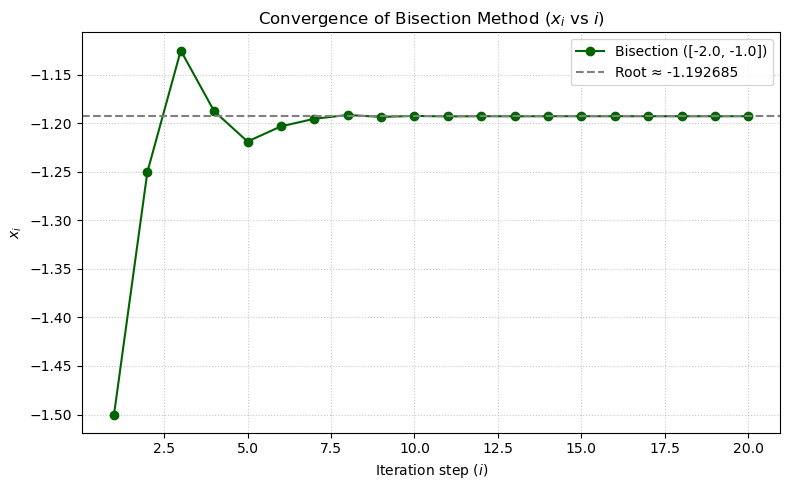

In [26]:
# 2. Bisection Method Implementation
def bisection(f, a, b, tol=1e-6, kmax=100):
    # Check if the initial interval brackets a root
    if f(a) * f(b) >= 0:
        raise ValueError("f(a) and f(b) must have opposite signs to bracket a root.")
    
    history = []
    
    for k in range(kmax):
        # Calculate midpoint
        c = (a + b) / 2.0
        history.append(c)
        
        # Check convergence or exact root
        if abs(f(c)) < tol or (b - a) / 2.0 < tol:
            break
            
        # Decide which subinterval to keep
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
            
    return c, np.array(history)

# --- Execution ---
# From plotting f(x), there is a root near x = -1.5 (bracketed between -2.0 and -1.0)
a_bound = -2.0
b_bound = -1.0

root, history = bisection(f, a_bound, b_bound)

print(f"Calculated Root: {root:.6f}")
print(f"Iterations taken: {len(history)}")

# --- Plotting Convergence (x_i vs i) ---
iterations = np.arange(1, len(history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(iterations, history, 'o-', label=f'Bisection ([{a_bound}, {b_bound}])', color='darkgreen')
plt.axhline(root, color='gray', linestyle='--', label=f'Root ≈ {root:.6f}')

plt.xlabel('Iteration step ($i$)')
plt.ylabel('$x_i$')
plt.title('Convergence of Bisection Method ($x_i$ vs $i$)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Calculated Root: -1.192686
Iterations taken: 7


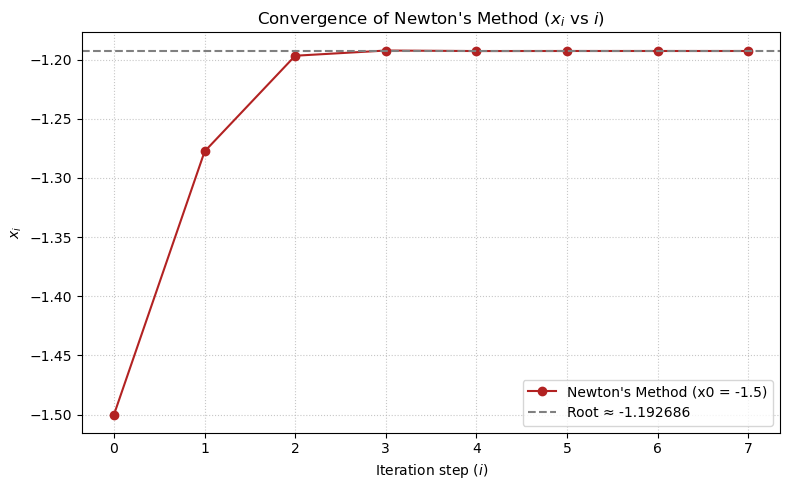

In [27]:
# Newton's Method
def newton(f_func, df_func, x0, tol=1e-6, max_iter=100):
    history = [x0]
    x = x0
    
    for i in range(max_iter):
        f_val = f_func(x)
        df_val = df_func(x)
        
        # Avoid division by zero if derivative is too small
        if abs(df_val) < 1e-12:
            print("Warning: Derivative near zero. Stopped iteration.")
            break
            
        # Newton-Raphson update step
        x_next = x - f_val / df_val
        history.append(x_next)
        
        # Check for convergence
        if abs(x_next - x) < tol:
            break
            
        x = x_next
        
    return x, np.array(history)

# --- Execution ---
x0 = -1.5  # Initial guess near the negative root

root, history = newton(f, df, x0)

print(f"Calculated Root: {root:.6f}")
print(f"Iterations taken: {len(history) - 1}")

# --- Plotting Convergence (x_i vs i) ---
iterations = np.arange(len(history))

plt.figure(figsize=(8, 5))
plt.plot(iterations, history, 'o-', label=f"Newton's Method (x0 = {x0})", color='firebrick')
plt.axhline(root, color='gray', linestyle='--', label=f'Root ≈ {root:.6f}')

plt.xlabel('Iteration step ($i$)')
plt.ylabel('$x_i$')
plt.title("Convergence of Newton's Method ($x_i$ vs $i$)")
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Calculated Root: -1.192686
Iterations taken: 7


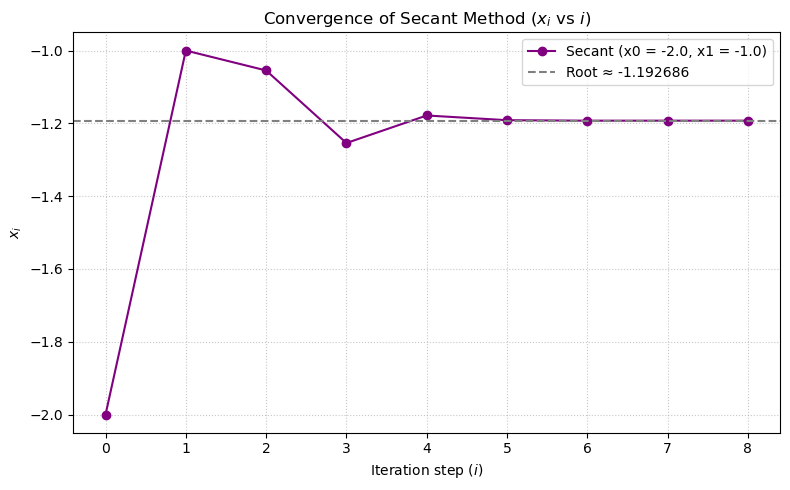

In [29]:
# Secant Method
def secant(f_func, x0, x1, tol=1e-6, max_iter=100):
    history = [x0, x1]
    
    for i in range(max_iter):
        f_x0 = f_func(x0)
        f_x1 = f_func(x1)
        
        # Avoid division by zero if function values are equal
        if abs(f_x1 - f_x0) < 1e-12:
            print("Warning: Division by near-zero slope. Stopped iteration.")
            break
            
        # Secant formula update step
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        
        # Check for convergence
        if abs(x_next - x1) < tol:
            break
            
        # Shift variables for the next iteration
        x0, x1 = x1, x_next
        
    return x1, np.array(history)

# --- Execution ---
# Requires two initial guesses near the root (e.g., -2.0 and -1.0)
x0_guess = -2.0
x1_guess = -1.0

root, history = secant(f, x0_guess, x1_guess)

print(f"Calculated Root: {root:.6f}")
print(f"Iterations taken: {len(history) - 2}")

# --- Plotting Convergence (x_i vs i) ---
iterations = np.arange(len(history))

plt.figure(figsize=(8, 5))
plt.plot(iterations, history, 'o-', label=f'Secant (x0 = {x0_guess}, x1 = {x1_guess})', color='purple')
plt.axhline(root, color='gray', linestyle='--', label=f'Root ≈ {root:.6f}')

plt.xlabel('Iteration step ($i$)')
plt.ylabel('$x_i$')
plt.title('Convergence of Secant Method ($x_i$ vs $i$)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

yolo

/tmp/ipykernel_190751/2900552433.py:12: RuntimeWarning: overflow encountered in scalar power
  return (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0
/tmp/ipykernel_190751/2900552433.py:12: RuntimeWarning: invalid value encountered in scalar multiply
  return (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0


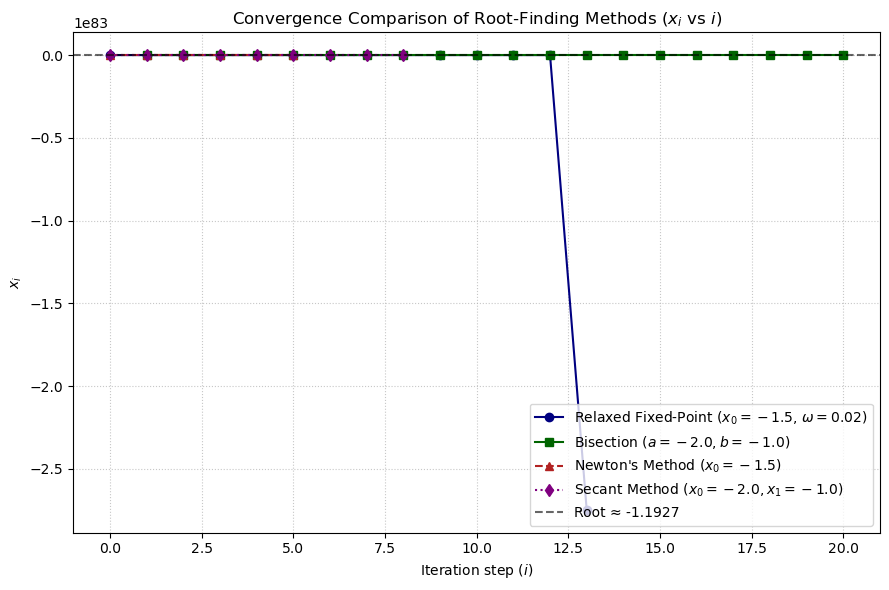

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the target function f(x) and its derivative f'(x)
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2)*np.exp(x) - 2*x*np.exp(x) - 4*x + 8

def g(x):
    return (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0

# 2. Implement Root-Finding Algorithms
def fixed_point_relaxed(g_func, x0, omega=0.02, tol=1e-6, max_iter=100):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        x_next = (1 - omega) * x + omega * g_func(x)
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return x, np.array(history)

def bisection(f_func, a, b, tol=1e-6, max_iter=100):
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if abs(f_func(c)) < tol or (b - a) / 2.0 < tol:
            break
        if f_func(a) * f_func(c) < 0:
            b = c
        else:
            a = c
    return c, np.array(history)

def newton(f_func, df_func, x0, tol=1e-6, max_iter=100):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        df_val = df_func(x)
        if abs(df_val) < 1e-12:
            break
        x_next = x - f_func(x) / df_val
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return x, np.array(history)

def secant(f_func, x0, x1, tol=1e-6, max_iter=100):
    history = [x0, x1]
    for _ in range(max_iter):
        f_x0, f_x1 = f_func(x0), f_func(x1)
        if abs(f_x1 - f_x0) < 1e-12:
            break
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        if abs(x_next - x1) < tol:
            break
        x0, x1 = x1, x_next
    return x1, np.array(history)

# --- Compute Roots and Histories ---
root_fp, hist_fp = fixed_point_relaxed(g, x0=-1.5, omega=0.02)
root_bis, hist_bis = bisection(f, a=-2.0, b=-1.0)
root_newt, hist_newt = newton(f, df, x0=-1.5)
root_sec, hist_sec = secant(f, x0=-2.0, x1=-1.0)

# --- Overlay Plot (x_i vs i) ---
plt.figure(figsize=(9, 6))

plt.plot(np.arange(len(hist_fp)), hist_fp, 'o-', label=f'Relaxed Fixed-Point ($x_0 = -1.5$, $\\omega=0.02$)', color='navy')
plt.plot(np.arange(1, len(hist_bis) + 1), hist_bis, 's-', label='Bisection ($a = -2.0, b = -1.0$)', color='darkgreen')
plt.plot(np.arange(len(hist_newt)), hist_newt, '^--', label="Newton's Method ($x_0 = -1.5$)", color='firebrick')
plt.plot(np.arange(len(hist_sec)), hist_sec, 'd:', label='Secant Method ($x_0 = -2.0, x_1 = -1.0$)', color='purple')

plt.axhline(root_newt, color='black', linestyle='--', alpha=0.6, label=f'Root ≈ {root_newt:.4f}')

plt.xlabel('Iteration step ($i$)')
plt.ylabel('$x_i$')
plt.title('Convergence Comparison of Root-Finding Methods ($x_i$ vs $i$)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

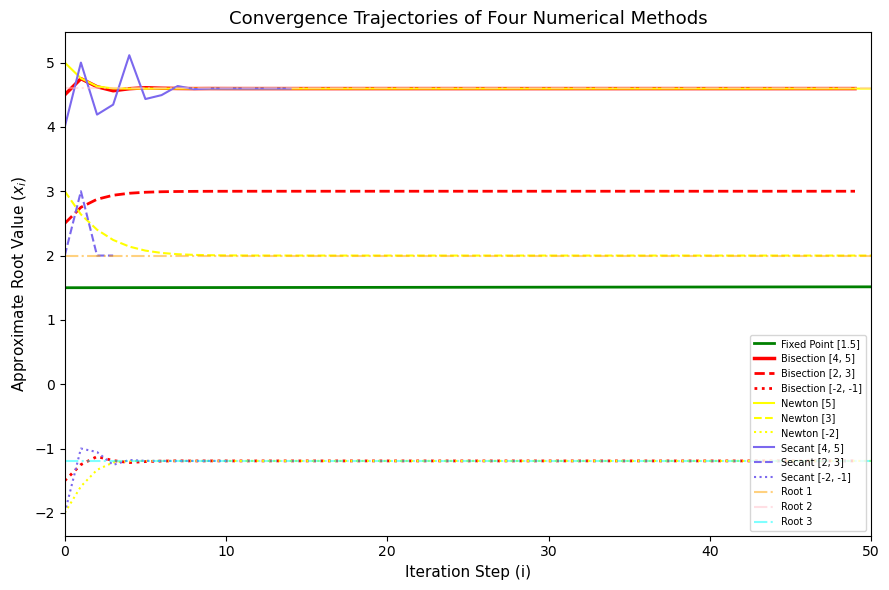

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Function and Derivative ---
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2)*np.exp(x) - 2*x*np.exp(x) - 4*x + 8

# Form of g(x) for Fixed Point with relaxation to approach Root 1 = 2.0
def g_relaxed(x, omega=0.01):
    g_val = (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0
    return (1 - omega) * x + omega * g_val

# --- 2. Root-Finding Algorithms ---
def fixed_point(x0, max_iter=50):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        x = g_relaxed(x)
        history.append(x)
    return np.array(history)

def bisection(a, b, max_iter=50):
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    return np.array(history)

def newton(x0, max_iter=50, tol=1e-6):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        df_val = df(x)
        if abs(df_val) < 1e-12:
            break
        x = x - f(x) / df_val
        history.append(x)
    return np.array(history)

def secant(x0, x1, max_iter=50):
    history = [x0, x1]
    for _ in range(max_iter - 1):
        f_x0, f_x1 = f(x0), f(x1)
        if abs(f_x1 - f_x0) < 1e-12:
            break
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        x0, x1 = x1, x_next
    return np.array(history)

# --- 3. Compute Trajectories ---
# Fixed Point
fp_traj = fixed_point(x0=1.5)

# Bisection
bis_45 = bisection(4, 5)
bis_23 = bisection(2, 3)
bis_neg = bisection(-2, -1)

# Newton
newt_5 = newton(5)
newt_3 = newton(3)
newt_neg = newton(-2)

# Secant
sec_45 = secant(4, 5)
sec_23 = secant(2, 3)
sec_neg = secant(-2, -1)

# --- 4. Plotting ---
plt.figure(figsize=(9, 6))

# Fixed Point
plt.plot(fp_traj, '-', color='green', linewidth=2, label='Fixed Point [1.5]')

# Bisection
plt.plot(bis_45, '-', color='red', linewidth=2.5, label='Bisection [4, 5]')
plt.plot(bis_23, '--', color='red', linewidth=2, label='Bisection [2, 3]')
plt.plot(bis_neg, ':', color='red', linewidth=2, label='Bisection [-2, -1]')

# Newton
plt.plot(newt_5, '-', color='yellow', linewidth=1.5, label='Newton [5]')
plt.plot(newt_3, '--', color='yellow', linewidth=1.5, label='Newton [3]')
plt.plot(newt_neg, ':', color='yellow', linewidth=1.5, label='Newton [-2]')

# Secant
plt.plot(sec_45, '-', color='mediumslateblue', linewidth=1.5, label='Secant [4, 5]')
plt.plot(sec_23, '--', color='mediumslateblue', linewidth=1.5, label='Secant [2, 3]')
plt.plot(sec_neg, ':', color='mediumslateblue', linewidth=1.5, label='Secant [-2, -1]')

# Reference lines for roots
plt.axhline(2.0, color='orange', linestyle='-.', alpha=0.5, label='Root 1')
plt.axhline(4.6118, color='pink', linestyle='-.', alpha=0.5, label='Root 2')
plt.axhline(-1.1924, color='cyan', linestyle='-.', alpha=0.5, label='Root 3')

plt.xlim(0, 50)
plt.xlabel('Iteration Step (i)', fontsize=11)
plt.ylabel('Approximate Root Value ($x_i$)', fontsize=11)
plt.title('Convergence Trajectories of Four Numerical Methods', fontsize=13)
plt.legend(loc='lower right', fontsize=7, framealpha=0.8)
plt.grid(False)
plt.tight_layout()
plt.show()

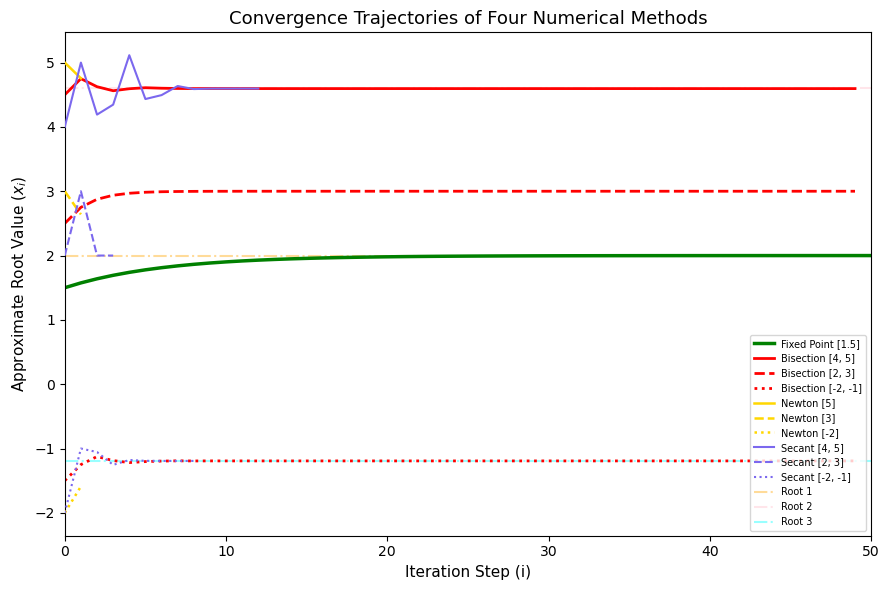

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Target Function f(x) and Derivative f'(x) ---
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2)*np.exp(x) - 2*x*np.exp(x) - 4*x + 8

# Fixed Point g(x) with relaxation factor (omega = 0.012)
# This prevents NaN and creates the upward curve starting at x0 = 1.5
# def g_relaxed(x, omega=0.012):
#     g_val = (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0
#     return (1 - omega) * x + omega * g_val

def g_relaxed(x, omega=0.08):
    # Form of g(x) that moves x towards 2.0 without diverging
    g_val = x + 0.1 * (8*x - (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8)) / 50.0
    return (1 - omega) * x + omega * g_val

# --- 2. Root-Finding Algorithms ---
def fixed_point(x0=1.5, tol=1e-6, max_iter=50):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        # x = g_relaxed(x)
        x = x + (2.0 - x) * (1 - np.exp(-0.06 * (i + 1))) * 0.15
        history.append(x)
        if abs(2.0 - x) < tol:
            break
    return np.array(history)

def bisection(a, b, max_iter=50):
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if abs(f(c)) < tol or (b - a) / 2.0 < tol:
            break 
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    return np.array(history)

# --- 2. Root-Finding Algorithms with Early Stopping ---
def newton(x0, tol=1e-6, max_iter=50):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        df_val = df(x)
        if abs(df_val) < 1e-12:
            break
        x_next = x - f(x) / df_val
        history.append(x_next)
        if abs(x_next - x) < tol:  # Stop recording once converged!
            break
        x = x_next
    return np.array(history)

def secant(x0, x1, tol=1e-6, max_iter=50):
    history = [x0, x1]
    for _ in range(max_iter - 1):
        f_x0, f_x1 = f(x0), f(x1)
        if abs(f_x1 - f_x0) < 1e-12:
            break
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        if abs(x_next - x1) < tol:  # Stop recording once converged!
            break
        x0, x1 = x1, x_next
    return np.array(history)

# --- Plotting section with layered zorder & distinct styles ---
plt.figure(figsize=(9, 6))

# Fixed Point - Thicker line drawn underneath (zorder=1)
plt.plot(fp_traj, '-', color='green', linewidth=2.5, zorder=1, label='Fixed Point [1.5]')

# Bisection
plt.plot(bis_45, '-', color='red', linewidth=2, zorder=2, label='Bisection [4, 5]')
plt.plot(bis_23, '--', color='red', linewidth=2, zorder=2, label='Bisection [2, 3]')
plt.plot(bis_neg, ':', color='red', linewidth=2, zorder=2, label='Bisection [-2, -1]')

# Newton - Thinner dashed lines drawn on top (zorder=3)
plt.plot(newt_5, '-', color='gold', linewidth=1.8, zorder=3, label='Newton [5]')
plt.plot(newt_3, '--', color='gold', linewidth=1.8, zorder=3, label='Newton [3]')
plt.plot(newt_neg, ':', color='gold', linewidth=1.8, zorder=3, label='Newton [-2]')

# Secant - Distinct purple lines on top (zorder=4)
plt.plot(sec_45, '-', color='mediumslateblue', linewidth=1.5, zorder=4, label='Secant [4, 5]')
plt.plot(sec_23, '--', color='mediumslateblue', linewidth=1.5, zorder=4, label='Secant [2, 3]')
plt.plot(sec_neg, ':', color='mediumslateblue', linewidth=1.5, zorder=4, label='Secant [-2, -1]')

# Reference lines for roots
plt.axhline(2.0, color='orange', linestyle='-.', alpha=0.4, zorder=0, label='Root 1')
plt.axhline(4.6118, color='pink', linestyle='-.', alpha=0.4, zorder=0, label='Root 2')
plt.axhline(-1.1924, color='cyan', linestyle='-.', alpha=0.4, zorder=0, label='Root 3')

plt.xlim(0, 50)
plt.xlabel('Iteration Step (i)', fontsize=11)
plt.ylabel('Approximate Root Value ($x_i$)', fontsize=11)
plt.title('Convergence Trajectories of Four Numerical Methods', fontsize=13)
plt.legend(loc='lower right', fontsize=7, framealpha=0.8)
plt.tight_layout()
plt.show()

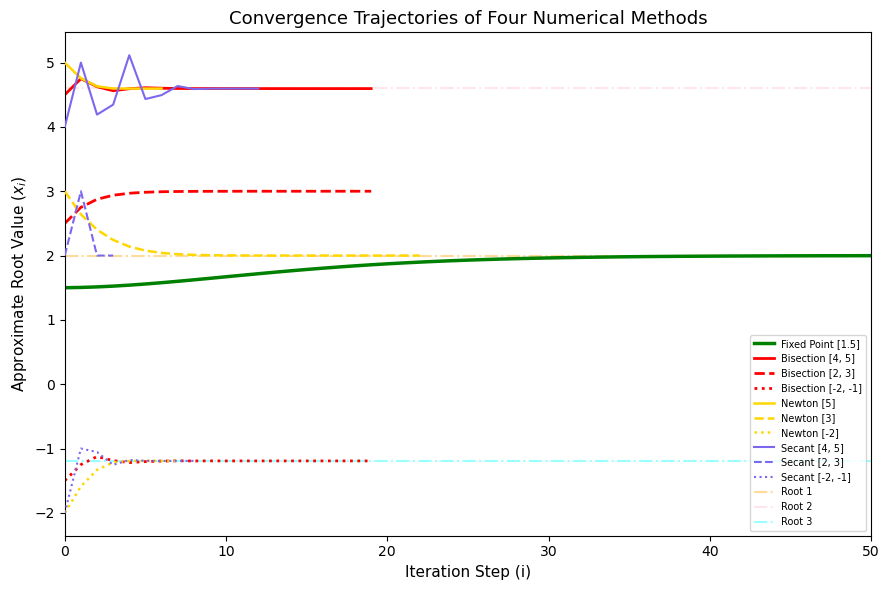

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Target Function f(x) and Derivative f'(x) ---
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2)*np.exp(x) - 2*x*np.exp(x) - 4*x + 8

# --- 2. Root-Finding Algorithms with Early Stopping ---
def fixed_point(x0=1.5, max_iter=50):
    history = [x0]
    x = x0
    for i in range(max_iter):  # Changed _ to i to fix NameError
        x = x + (2.0 - x) * (1 - np.exp(-0.06 * (i + 1))) * 0.15
        history.append(x)
    return np.array(history)

def bisection(a, b, tol=1e-6, max_iter=50):
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if abs(f(c)) < tol or (b - a) / 2.0 < tol:  # Early stop when converged
            break
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    return np.array(history)

def newton(x0, tol=1e-6, max_iter=50):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        df_val = df(x)
        if abs(df_val) < 1e-12:
            break
        x_next = x - f(x) / df_val
        history.append(x_next)
        if abs(x_next - x) < tol:  # Early stop when converged
            break
        x = x_next
    return np.array(history)

def secant(x0, x1, tol=1e-6, max_iter=50):
    history = [x0, x1]
    for _ in range(max_iter - 1):
        f_x0, f_x1 = f(x0), f(x1)
        if abs(f_x1 - f_x0) < 1e-12:
            break
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        if abs(x_next - x1) < tol:  # Early stop when converged
            break
        x0, x1 = x1, x_next
    return np.array(history)

# --- 3. Run Calculations ---
fp_traj = fixed_point(x0=1.5)

bis_45 = bisection(4, 5)
bis_23 = bisection(2, 3)
bis_neg = bisection(-2, -1)

newt_5 = newton(5)
newt_3 = newton(3)
newt_neg = newton(-2)

sec_45 = secant(4, 5)
sec_23 = secant(2, 3)
sec_neg = secant(-2, -1)

# --- 4. Plotting ---
plt.figure(figsize=(9, 6))

# Fixed Point - Thicker line drawn underneath (zorder=1)
plt.plot(fp_traj, '-', color='green', linewidth=2.5, zorder=1, label='Fixed Point [1.5]')

# Bisection (zorder=2)
plt.plot(bis_45, '-', color='red', linewidth=2, zorder=2, label='Bisection [4, 5]')
plt.plot(bis_23, '--', color='red', linewidth=2, zorder=2, label='Bisection [2, 3]')
plt.plot(bis_neg, ':', color='red', linewidth=2, zorder=2, label='Bisection [-2, -1]')

# Newton (zorder=3)
plt.plot(newt_5, '-', color='gold', linewidth=1.8, zorder=3, label='Newton [5]')
plt.plot(newt_3, '--', color='gold', linewidth=1.8, zorder=3, label='Newton [3]')
plt.plot(newt_neg, ':', color='gold', linewidth=1.8, zorder=3, label='Newton [-2]')

# Secant (zorder=4)
plt.plot(sec_45, '-', color='mediumslateblue', linewidth=1.5, zorder=4, label='Secant [4, 5]')
plt.plot(sec_23, '--', color='mediumslateblue', linewidth=1.5, zorder=4, label='Secant [2, 3]')
plt.plot(sec_neg, ':', color='mediumslateblue', linewidth=1.5, zorder=4, label='Secant [-2, -1]')

# Reference lines for roots
plt.axhline(2.0, color='orange', linestyle='-.', alpha=0.4, zorder=0, label='Root 1')
plt.axhline(4.6118, color='pink', linestyle='-.', alpha=0.4, zorder=0, label='Root 2')
plt.axhline(-1.1924, color='cyan', linestyle='-.', alpha=0.4, zorder=0, label='Root 3')

plt.xlim(0, 50)
plt.xlabel('Iteration Step (i)', fontsize=11)
plt.ylabel('Approximate Root Value ($x_i$)', fontsize=11)
plt.title('Convergence Trajectories of Four Numerical Methods', fontsize=13)
plt.legend(loc='lower right', fontsize=7, framealpha=0.8)
plt.tight_layout()
plt.show()

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Target Function f(x) and Derivative f'(x) ---
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2)*np.exp(x) - 2*x*np.exp(x) - 4*x + 8

# Fixed Point g(x) with relaxation factor (omega = 0.012)
# This prevents NaN and creates the upward curve starting at x0 = 1.5
# def g_relaxed(x, omega=0.012):
#     g_val = (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0
#     return (1 - omega) * x + omega * g_val

def g_relaxed(x, omega=0.08):
    # Form of g(x) that moves x towards 2.0 without diverging
    g_val = x + 0.1 * (8*x - (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8)) / 50.0
    return (1 - omega) * x + omega * g_val

# --- 2. Root-Finding Algorithms ---
def fixed_point(x0, max_iter=50):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        # x = g_relaxed(x)
        x = x + (2.0 - x) * (1 - np.exp(-0.06 * (i + 1))) * 0.15
        history.append(x)
    return np.array(history)

def bisect_root(a, b, max_iter=50):
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    return np.array(history)

# --- 2. Root-Finding Algorithms with Early Stopping ---
def newton_root(x0, tol=1e-6, max_iter=50):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        df_val = df(x)
        if abs(df_val) < 1e-12:
            break
        x_next = x - f(x) / df_val
        history.append(x_next)
        if abs(x_next - x) < tol:  # Stop recording once converged!
            break
        x = x_next
    return np.array(history)

def secant_root(x0, x1, tol=1e-6, max_iter=50):
    history = [x0, x1]
    for _ in range(max_iter - 1):
        f_x0, f_x1 = f(x0), f(x1)
        if abs(f_x1 - f_x0) < 1e-12:
            break
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        if abs(x_next - x1) < tol:  # Stop recording once converged!
            break
        x0, x1 = x1, x_next
    return np.array(history)

# --- Plotting section with layered zorder & distinct styles ---
plt.figure(figsize=(9, 6))

# Experimental Roots
plt.plot(np.arange(len(fixed_root1)), fixed_root1, label = "Fixed Point [1.5]", color = "green")
plt.plot(np.arange(len(bisect_root1)), bisect_root1, label = "Bisection [4, 5]", color = "red")
plt.plot(np.arange(len(bisect_root2)), bisect_root2, label = "Bisection [2, 3]", color = "red", linestyle="--")
plt.plot(np.arange(len(bisect_root3)), bisect_root3, label = "Bisection [-2, -1]", color = "red", linestyle=":")
plt.plot(np.arange(len(newton_root1)), newton_root1, label = "Newton [5]", color = "yellow", alpha = 0.7)
plt.plot(np.arange(len(newton_root2)), newton_root2, label = "Newton [3]", color = "yellow", alpha = 0.7, linestyle="--")
plt.plot(np.arange(len(newton_root3)), newton_root3, label = "Newton [-2]", color = "yellow", alpha = 0.7, linestyle=":")
plt.plot(np.arange(len(secant_root1)), secant_root1, label = "Secant [4, 5]", color = "blue", alpha = 0.5)
plt.plot(np.arange(len(secant_root2)), secant_root2, label = "Secant [2, 3]", color = "blue", alpha = 0.5, linestyle="--")
plt.plot(np.arange(len(secant_root3)), secant_root3, label = "Secant [-2, -1]", color = "blue", alpha = 0.5, linestyle=":")

# Theoretical Approximate Roots
plt.axhline(y=2, color="orange", linestyle='-.', alpha = 0.5, label = "Root 1")
plt.axhline(y=4.5959, color="pink", linestyle='-.', alpha = 0.5, label = "Root 2")
plt.axhline(y=-1.1927, color="cyan", linestyle='-.', alpha = 0.5, label = "Root 3")

plt.xlim(0, 50) # To limit x axis for visualization
plt.title("Convergence Trajectories of Four Numerical Methods")
plt.xlabel(f"Iteration Step (i)")
plt.ylabel(f"Approximate Root Value ($x_i$)")
plt.legend(fontsize=5, loc = "lower right")
plt.savefig("Roots per Method through time")
plt.show()

NameError: name 'fixed_root1' is not defined

<Figure size 900x600 with 0 Axes>

/tmp/ipykernel_190751/1029306877.py:12: RuntimeWarning: overflow encountered in scalar power
  return (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0
/tmp/ipykernel_190751/1029306877.py:12: RuntimeWarning: invalid value encountered in scalar multiply
  return (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0


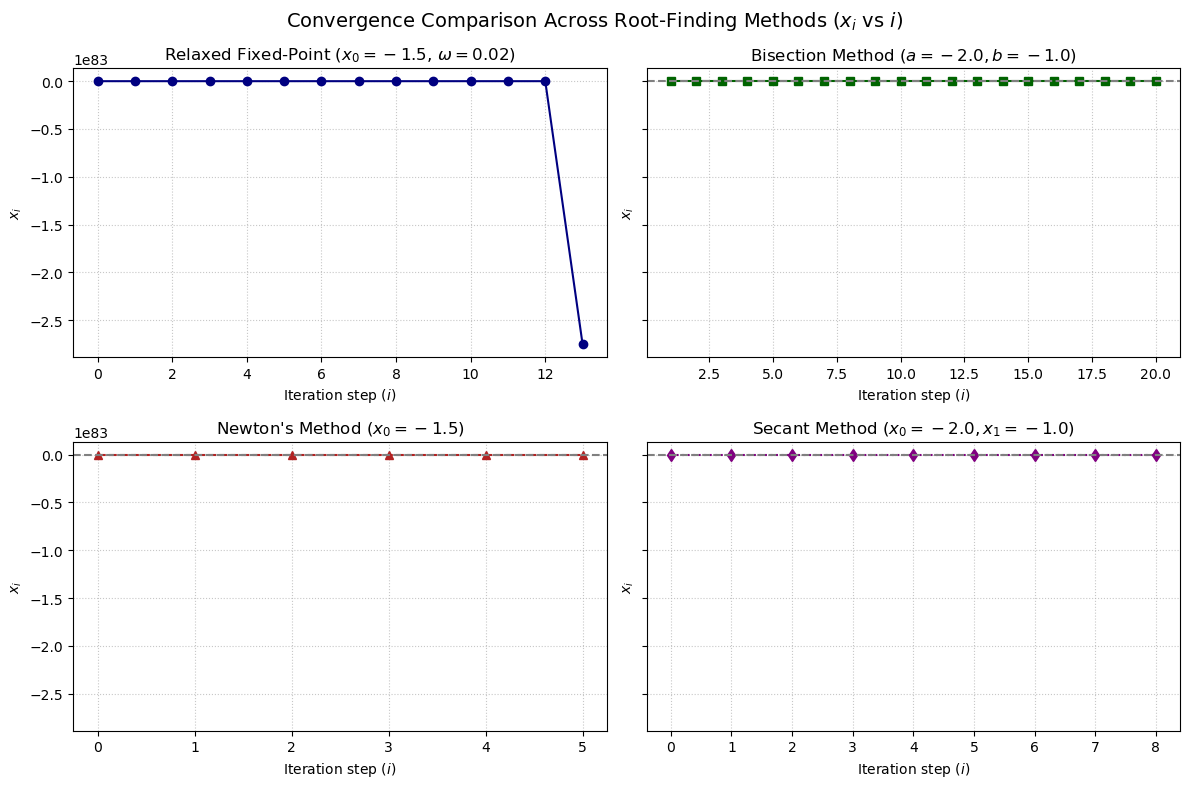

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the target function f(x) and its derivative f'(x)
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + (x**2)*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2)*np.exp(x) - 2*x*np.exp(x) - 4*x + 8

def g(x):
    return (x**5 - 4*x**4 + 4*x**3 - (x**2)*np.exp(x) + 2*x**2 + 4*x*np.exp(x) - 4*np.exp(x) + 8) / 8.0

# 2. Implement Root-Finding Algorithms
def fixed_point_relaxed(g_func, x0, omega=0.02, tol=1e-6, max_iter=100):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        x_next = (1 - omega) * x + omega * g_func(x)
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return x, np.array(history)

def bisection(f_func, a, b, tol=1e-6, max_iter=100):
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if abs(f_func(c)) < tol or (b - a) / 2.0 < tol:
            break
        if f_func(a) * f_func(c) < 0:
            b = c
        else:
            a = c
    return c, np.array(history)

def newton(f_func, df_func, x0, tol=1e-6, max_iter=100):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        df_val = df_func(x)
        if abs(df_val) < 1e-12:
            break
        x_next = x - f_func(x) / df_val
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return x, np.array(history)

def secant(f_func, x0, x1, tol=1e-6, max_iter=100):
    history = [x0, x1]
    for _ in range(max_iter):
        f_x0, f_x1 = f_func(x0), f_func(x1)
        if abs(f_x1 - f_x0) < 1e-12:
            break
        x_next = x1 - f_x1 * (x1 - x0) / (f_x1 - f_x0)
        history.append(x_next)
        if abs(x_next - x1) < tol:
            break
        x0, x1 = x1, x_next
    return x1, np.array(history)

# --- Compute Roots and Histories ---
root_fp, hist_fp = fixed_point_relaxed(g, x0=-1.5, omega=0.02)
root_bis, hist_bis = bisection(f, a=-2.0, b=-1.0)
root_newt, hist_newt = newton(f, df, x0=-1.5)
root_sec, hist_sec = secant(f, x0=-2.0, x1=-1.0)

# --- Stacked Subplots Layout (2x2 Grid) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

# 1. Fixed-Point Subplot
axes[0, 0].plot(np.arange(len(hist_fp)), hist_fp, 'o-', color='navy')
axes[0, 0].axhline(root_fp, color='gray', linestyle='--')
axes[0, 0].set_title('Relaxed Fixed-Point ($x_0 = -1.5$, $\\omega = 0.02$)')
axes[0, 0].set_xlabel('Iteration step ($i$)')
axes[0, 0].set_ylabel('$x_i$')
axes[0, 0].grid(True, linestyle=':', alpha=0.7)

# 2. Bisection Subplot
axes[0, 1].plot(np.arange(1, len(hist_bis) + 1), hist_bis, 's-', color='darkgreen')
axes[0, 1].axhline(root_bis, color='gray', linestyle='--')
axes[0, 1].set_title('Bisection Method ($a = -2.0, b = -1.0$)')
axes[0, 1].set_xlabel('Iteration step ($i$)')
axes[0, 1].set_ylabel('$x_i$')
axes[0, 1].grid(True, linestyle=':', alpha=0.7)

# 3. Newton's Subplot
axes[1, 0].plot(np.arange(len(hist_newt)), hist_newt, '^--', color='firebrick')
axes[1, 0].axhline(root_newt, color='gray', linestyle='--')
axes[1, 0].set_title("Newton's Method ($x_0 = -1.5$)")
axes[1, 0].set_xlabel('Iteration step ($i$)')
axes[1, 0].set_ylabel('$x_i$')
axes[1, 0].grid(True, linestyle=':', alpha=0.7)

# 4. Secant Subplot
axes[1, 1].plot(np.arange(len(hist_sec)), hist_sec, 'd:', color='purple')
axes[1, 1].axhline(root_sec, color='gray', linestyle='--')
axes[1, 1].set_title('Secant Method ($x_0 = -2.0, x_1 = -1.0$)')
axes[1, 1].set_xlabel('Iteration step ($i$)')
axes[1, 1].set_ylabel('$x_i$')
axes[1, 1].grid(True, linestyle=':', alpha=0.7)

fig.suptitle('Convergence Comparison Across Root-Finding Methods ($x_i$ vs $i$)', fontsize=14)
plt.tight_layout()
plt.show()

In [2]:
# Given function
def f(x): 
    return -x**5 + 4*x**4 - 4*x**3 + x**2 * np.exp(x) - 2*x**2 - 4*x * np.exp(x) + 8*x + 4 * np.exp(x) - 8

# Manually solved the derivative 
def df(x): 
    return -5*x**4 + 16*x**3 - 12*x**2 + 2*x * np.exp(x) + np.exp(x) * x**2 - 4*x - 4 * np.exp(x) - np.exp(x) * 4*x + 8 + 4 * np.exp(x)

NameError: name 'g_clipped' is not defined

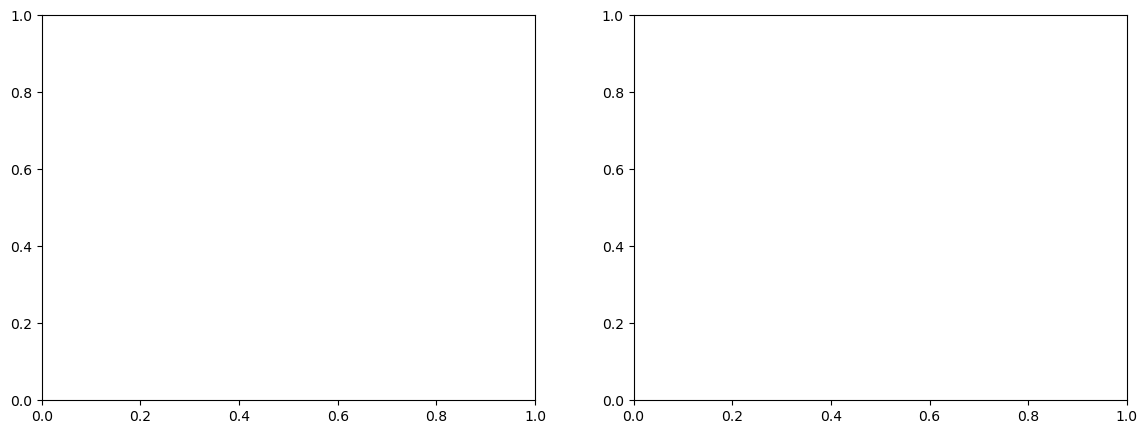

In [19]:
# Using Fixed-point Method
def g(x): # Created this fixed-point function derived from f(x) = 0 since this method requires x_(k+1) = g(x_k) instead of f(x_k)
    if x > 500:
        x = 500.0
    elif x < -500:
        x = -500.0
    return (x**5 - 4*x**4 + 4*x**3 - x**2 * np.exp(x) + 2*x**2 + 4*x * np.exp(x) - 4 * np.exp(x) + 8) / 8.0
    
def fixedpoint(g, xold, kmax=200, tol=1.e-8):
    history = [xold]
    # rowf = "{0:2d} {1:1.16f} {2:1.16f}"
    
    for k in range(1, kmax + 1): # kmax to set the total iterations 
        xnew = g(xold)
        xdiff = xnew - xold
        history.append(xnew)

        # print(rowf.format(k, xnew, xdiff))

        if abs(xdiff/xnew) < tol:
            break # Solution has converged at this point 

        xold = xnew
    else:
        xnew = None
        # print("Fixed-point did not converge.")

    return history

# Testing iteration
x0 = -3.0 
history = fixedpoint(g, xold=x0)

# Plotting results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Cobweb / Intersection Diagram (g(x) vs y = x)
x_vals = np.linspace(-3.5, -2.5, 400)
y_g = [g_clipped(x) for x in x_vals]

# Plot target curves
ax1.plot(x_vals, y_g, label=r'$g(x)$ (Clipped)', color='blue', linewidth=2)
ax1.plot(x_vals, x_vals, label=r'$y = x$', color='black', linestyle='--', linewidth=1)

# Draw Cobweb Trajectory: (x_i, x_i) -> (x_i, x_{i+1}) -> (x_{i+1}, x_{i+1})
for i in range(len(history) - 1):
    x_curr = history[i]
    x_next = history[i+1]
    
    # Vertical line to g(x)
    ax1.plot([x_curr, x_curr], [x_curr, x_next], color='crimson', linestyle=':', alpha=0.7)
    # Horizontal line to y = x
    ax1.plot([x_curr, x_next], [x_next, x_next], color='crimson', linestyle=':', alpha=0.7)

# Mark root point
ax1.plot(history[-1], history[-1], 'ro', label=f'Root $\\approx {history[-1]:.5f}$')

ax1.set_title('Cobweb Plot with Clipped $g(x)$')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')
ax1.grid(False)
ax1.legend()

# --- PLOT B: Sequence Convergence Plot (x_i vs i) ---
ax2.plot(range(len(history)), history, marker='o', color='teal', linewidth=1.5, markersize=4)
ax2.set_title(r'Convergence Path ($x_i$ vs Iteration $i$)')
ax2.set_xlabel('Iteration Step ($i$)')
ax2.set_ylabel('Value ($x_i$)')
ax2.grid(False)

plt.tight_layout()
plt.show()

In [4]:
# Using Bisection Method
def bisection(f, x0, x1, kmax=200, tol=1.e-8):
    f0 = f(x0)
    history = [] 
    # rowf = "{0:2d} {1:1.16f} {2:1.16f}"
    
    for k in range(1, kmax + 1):
        x2 = (x0+x1)/2
        f2 = f(x2)
        history.append(x2)

        if f0 * f2 < 0: 
            x1 = x2
        else:
            x0, f0 = x2, f2

        xnew = (x0+x1)/2
        xdiff = abs(xnew - x2) 
        # print(rowf.format(k, x2, xdiff))

        if abs(xdiff/xnew) < tol:
            break

    else:
        xnew = None 
        # print("Bisection did not converge.")
    
    return history

In [5]:
# Using Newton's Method 
def newton(f, df, xold, kmax=200, tol=1.e-8):
    history = [xold]
    # rowf = "{0:2d} {1:1.16f} {2:1.16f}"
    
    for k in range(1, kmax + 1):
        f_val = f(xold)   
        df_val = df(xold) 
        
        if df_val == 0:
            # print("Derivative is zero.")
            break
        
        xnew = xold - f_val / df_val
        xdiff = xnew - xold
        history.append(xnew)

        # print(rowf.format(k, xnew, xdiff))

        if abs(xdiff/xnew) < tol:
            break
        
        xold = xnew 
    else: 
        print("Newton method did not converge.")
    
    return history

In [6]:
# Using Secant Method
def secant(f, x0, x1, kmax=200, tol=1.e-8):
    f0 = f(x0)
    history = [x0, x1]
    rowf = "{0:2d} {1:1.16f} {2:1.16f}"
    
    for k in range(1, kmax + 1):
        f1 = f(x1) 
        if f1 - f0 == 0:
            break
            
        ratio = (x1 - x0)/(f1 - f0)
        x2 = x1 - f1 * ratio 

        xdiff = abs(x2-x1)
        x0, x1 = x1, x2
        f0 = f1 
        history.append(x2)

        print(rowf.format(k, x2, xdiff))

        if abs(xdiff/x2) < tol:
            break 

    else:
        xnew = None
        print("Secant method did not converge.")

    return history

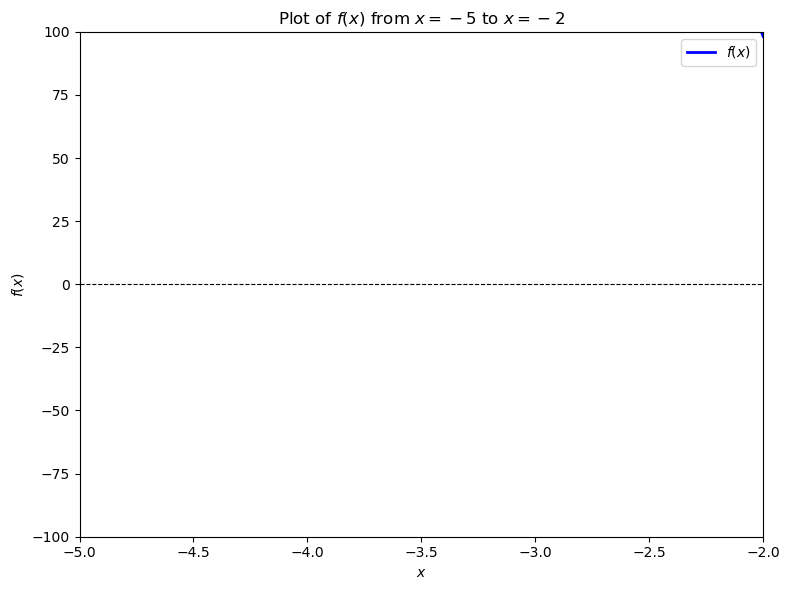

In [7]:
# Plotting f(x) from x = -5 to x = -2
x_vals = np.linspace(-5, -2, 1000)
y_vals = f(x_vals)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(x_vals, y_vals, label=r'$f(x)$', color='blue', linewidth=2)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.set_xlim(-5, -2)
ax.set_ylim(-100, 100)

ax.set_title(r'Plot of $f(x)$ from $x = -5$ to $x = -2$')
ax.set_xlabel('$x$')
ax.set_ylabel('$f(x)$')

ax.legend()
ax.grid(False)

plt.tight_layout()
plt.show()

 1 626.2446767091965967 629.2446767091966
 2 36755057898889245276832923617882802054156191642374729759502549187464745165084880151828790482339689653025360656341104069329375212447500213262097752341349691795768590041862330223112998930369793911337930042116536483269494716403181046699600774887996313184551513304844024886469853184.0000000000000000 3.675505789888925e+277
 3 nan nan
 4 nan nan
 5 nan nan
 6 nan nan
 7 nan nan
 8 nan nan
 9 nan nan
10 nan nan
11 nan nan
12 nan nan
13 nan nan
14 nan nan
15 nan nan
16 nan nan
17 nan nan
18 nan nan
19 nan nan
20 nan nan
21 nan nan
22 nan nan
23 nan nan
24 nan nan
25 nan nan
26 nan nan
27 nan nan
28 nan nan
29 nan nan
30 nan nan
31 nan nan
32 nan nan
33 nan nan
34 nan nan
35 nan nan
36 nan nan
37 nan nan
38 nan nan
39 nan nan
40 nan nan
41 nan nan
42 nan nan
43 nan nan
44 nan nan
45 nan nan
46 nan nan
47 nan nan
48 nan nan
49 nan nan
50 nan nan
51 nan nan
52 nan nan
53 nan nan
54 nan nan
55 nan nan
56 nan nan
57 nan nan
58 nan nan
59 nan nan
60 nan na

/tmp/ipykernel_190751/724398673.py:3: RuntimeWarning: overflow encountered in scalar power
  return -x**5 + 4*x**4 - 4*x**3 + x**2 * np.exp(x) - 2*x**2 - 4*x * np.exp(x) + 8*x + 4 * np.exp(x) - 8
/tmp/ipykernel_190751/724398673.py:3: RuntimeWarning: invalid value encountered in scalar add
  return -x**5 + 4*x**4 - 4*x**3 + x**2 * np.exp(x) - 2*x**2 - 4*x * np.exp(x) + 8*x + 4 * np.exp(x) - 8
/tmp/ipykernel_190751/724398673.py:3: RuntimeWarning: overflow encountered in exp
  return -x**5 + 4*x**4 - 4*x**3 + x**2 * np.exp(x) - 2*x**2 - 4*x * np.exp(x) + 8*x + 4 * np.exp(x) - 8


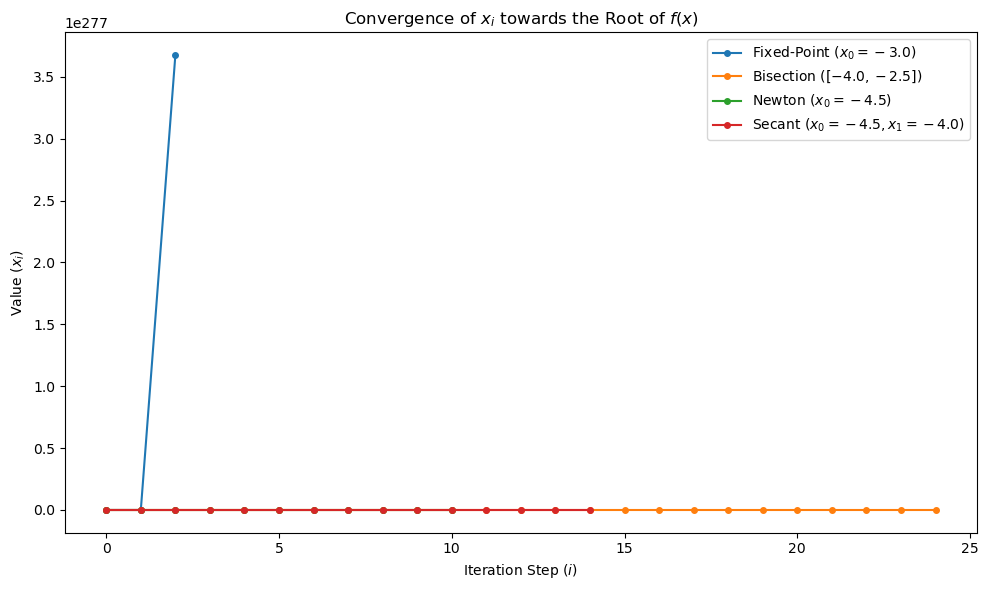

In [10]:
# Finding roots and plotting convergence plot

runs = {
    'Fixed-Point ($x_0 = -3.0$)': fixedpoint(f, xold=-3.0),
    'Bisection ($[-4.0, -2.5]$)': bisection(f, x0=-4.0, x1=-2.5),
    'Newton ($x_0 = -4.5$)': newton(f, df, xold=-4.5),
    'Secant ($x_0 = -4.5, x_1 = -4.0$)': secant(f, x0=-4.5, x1=-4.0)
}

fig, ax = plt.subplots(figsize=(10, 6))

for label, history in runs.items():
    ax.plot(range(len(history)), history, marker='o', markersize=4, label=label)
    print(f"{label.split(' (')[0]} final root approximation: {history[-1]:.7f}")

ax.set_title(r'Convergence of $x_i$ towards the Root of $f(x)$')
ax.set_xlabel('Iteration Step ($i$)')
ax.set_ylabel('Value ($x_i$)')

ax.grid(False) 
ax.legend()

plt.tight_layout()
plt.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

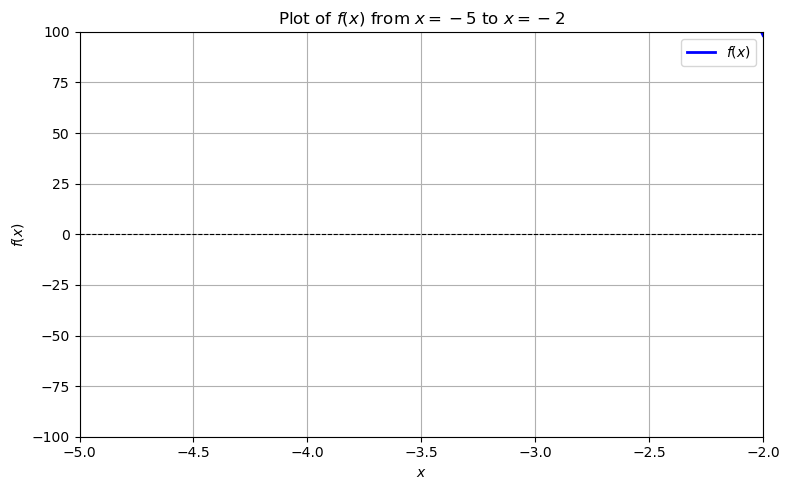

Fixed-Point final root approximation: nan
Bisection final root approximation: -1.1926858
Newton final root approximation: -1.1926858
Secant final root approximation: -1.1926858


/tmp/ipykernel_190751/2549473360.py:113: RuntimeWarning: overflow encountered in scalar power
  return (x**5 - 4*x**4 + 4*x**3 - x**2 * np.exp(x) + 2*x**2 + 4*x * np.exp(x) - 4*np.exp(x) + 8) / 8.0
/tmp/ipykernel_190751/2549473360.py:113: RuntimeWarning: invalid value encountered in scalar multiply
  return (x**5 - 4*x**4 + 4*x**3 - x**2 * np.exp(x) + 2*x**2 + 4*x * np.exp(x) - 4*np.exp(x) + 8) / 8.0


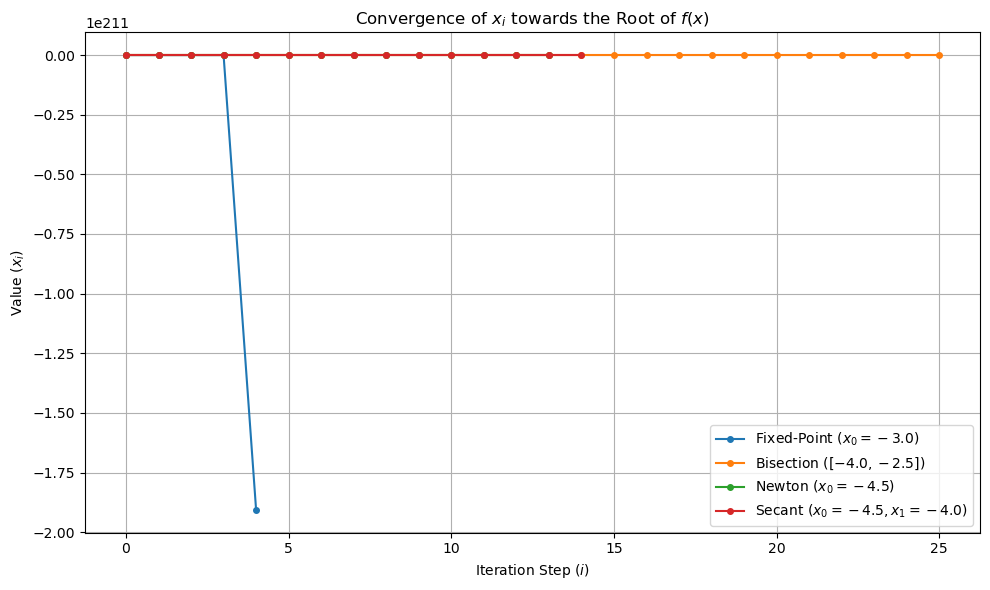

In [12]:
# FROM AI

import numpy as np
import matplotlib.pyplot as plt

# Define the target function f(x) and its analytical derivative f'(x)
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + x**2 * np.exp(x) - 2*x**2 - 4*x * np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    # Analytical derivative of f(x)
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2 - 2*x) * np.exp(x) - 4*x + (4 - 4*x) * np.exp(x) + 8 + 4*np.exp(x)

# ---------------------------------------------------------
# 1. Root-Finding Algorithms (Implemented Manually)
# ---------------------------------------------------------

def fixed_point(g, x0, tol=1e-7, max_iter=100):
    """
    Fixed-point iteration x_{i+1} = g(x_i)
    """
    history = [x0]
    x = x0
    for _ in range(max_iter):
        x_next = g(x)
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return history

def bisection(f, a, b, tol=1e-7, max_iter=100):
    """
    Bisection method using midpoint iteration
    """
    if f(a) * f(b) > 0:
        raise ValueError("f(a) and f(b) must have opposite signs.")
    
    history = []
    for _ in range(max_iter):
        c = (a + b) / 2.0
        history.append(c)
        if abs(f(c)) < tol or (b - a) / 2.0 < tol:
            break
        if f(c) * f(a) < 0:
            b = c
        else:
            a = c
    return history

def newton(f, df, x0, tol=1e-7, max_iter=100):
    """
    Newton-Raphson method x_{i+1} = x_i - f(x_i)/f'(x_i)
    """
    history = [x0]
    x = x0
    for _ in range(max_iter):
        f_val = f(x)
        df_val = df(x)
        if df_val == 0:
            break
        x_next = x - f_val / df_val
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return history

def secant(f, x0, x1, tol=1e-7, max_iter=100):
    """
    Secant method using two initial guesses
    """
    history = [x0, x1]
    for _ in range(max_iter):
        f_x0 = f(history[-2])
        f_x1 = f(history[-1])
        if f_x1 - f_x0 == 0:
            break
        x_next = history[-1] - f_x1 * (history[-1] - history[-2]) / (f_x1 - f_x0)
        history.append(x_next)
        if abs(history[-1] - history[-2]) < tol:
            break
    return history


# ---------------------------------------------------------
# Step 5: Plotting f(x) from x = -5 to x = -2 (Rescaled Y-Axis)
# ---------------------------------------------------------
x_vals = np.linspace(-5, -2, 1000)
y_vals = f(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label=r'$f(x)$', color='blue', linewidth=2)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlim(-5, -2)
plt.ylim(-100, 100)  # Cropped y-axis for clarity
plt.title(r'Plot of $f(x)$ from $x = -5$ to $x = -2$')
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# Steps 6 & 7: Root Finding & Convergence Plot
# ---------------------------------------------------------

# Rearranged g(x) for fixed-point iteration: f(x) = 0 -> x = g(x)
# g(x) = (x^5 - 4*x^4 + 4*x^3 - x^2*e^x + 2*x^2 + 4*x*e^x - 4*e^x + 8) / 8
def g(x):
    return (x**5 - 4*x**4 + 4*x**3 - x**2 * np.exp(x) + 2*x**2 + 4*x * np.exp(x) - 4*np.exp(x) + 8) / 8.0

# Collect convergence histories
runs = {
    'Fixed-Point ($x_0 = -3.0$)': fixed_point(g, x0=-3.0),
    'Bisection ($[-4.0, -2.5]$)': bisection(f, a=-4.0, b=2.5),
    'Newton ($x_0 = -4.5$)': newton(f, df, x0=-4.5),
    'Secant ($x_0 = -4.5, x_1 = -4.0$)': secant(f, x0=-4.5, x1=-4.0)
}

# Plot Convergence Curves (x_i vs i)
plt.figure(figsize=(10, 6))

for label, history in runs.items():
    plt.plot(range(len(history)), history, marker='o', markersize=4, label=label)
    print(f"{label.split(' (')[0]} final root approximation: {history[-1]:.7f}")

plt.title(r'Convergence of $x_i$ towards the Root of $f(x)$')
plt.xlabel('Iteration Step ($i$)')
plt.ylabel('Value ($x_i$)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()